<a href="https://colab.research.google.com/github/FallingFrost/robotics-practice/blob/main/Tutorial_4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Import libraries

In [10]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import cv2
from scipy import ndimage # multidimensional image processing
from skimage.color import rgb2hsv # image processing algorithms
from skimage import data #coins image

1. Read in images
2. Convert to greyscale
3. Histogram equalisation

/tmp/ipykernel_1203/1796827373.py:12: MatplotlibDeprecationWarning: Passing the range parameter of hist() positionally is deprecated since Matplotlib 3.9; the parameter will become keyword-only in 3.11.
  plt.hist(img.ravel(),256,[0,256]);  # show histogram. numpy.ravel() - flatten an image, i.e. 2D->1D
/tmp/ipykernel_1203/1796827373.py:13: MatplotlibDeprecationWarning: Passing the range parameter of hist() positionally is deprecated since Matplotlib 3.9; the parameter will become keyword-only in 3.11.
  plt.hist(equ.ravel(),256,[0,256]);


Text(0.5, 1.0, 'hist equalised')

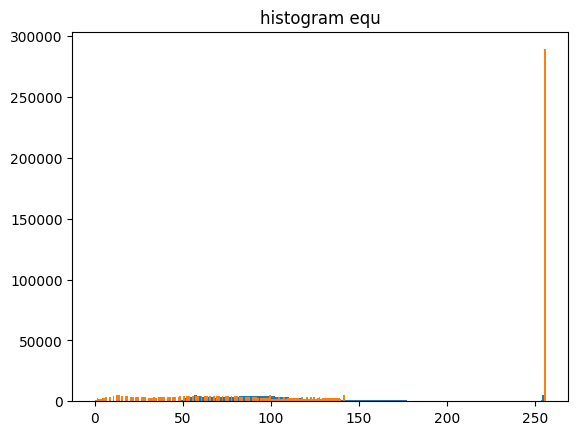

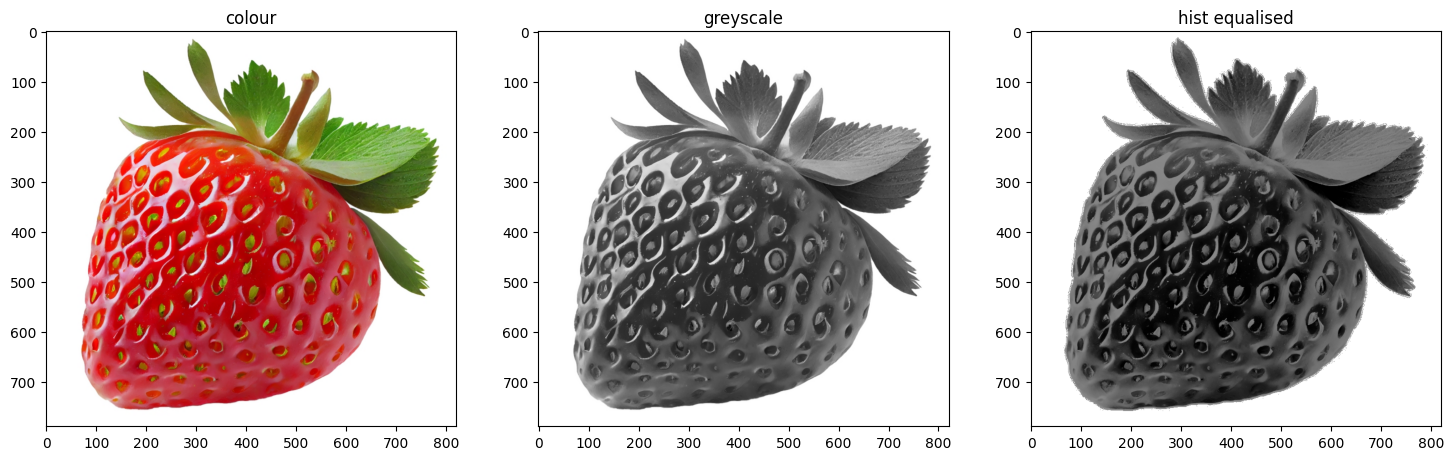

In [11]:
img = cv2.imread('/content/strawberry.jpg')
hsv_img = rgb2hsv(img)
colour = img.copy() # make a deep copy of the original image

img = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)  # conver to greyscale

img = cv2.imread('/content/strawberry.jpg', 0)  # read in as a greyscale image, alternative to line 1 and 4 combined

equ = cv2.equalizeHist(img)  # histogram equalisation

plt.figure()
plt.hist(img.ravel(),256,[0,256]);  # show histogram. numpy.ravel() - flatten an image, i.e. 2D->1D
plt.hist(equ.ravel(),256,[0,256]);
plt.title("histogram equ")

plt.figure(figsize=(18, 8))
plt.subplot(1,3,1)
plt.imshow(colour[:,:,::-1])
plt.title("colour")
plt.subplot(1,3,2)
plt.imshow(img,cmap="gray")
plt.title("greyscale")
plt.subplot(1,3,3)
plt.imshow(equ,cmap="gray")
plt.title("hist equalised")

Comparing different thresholding methods

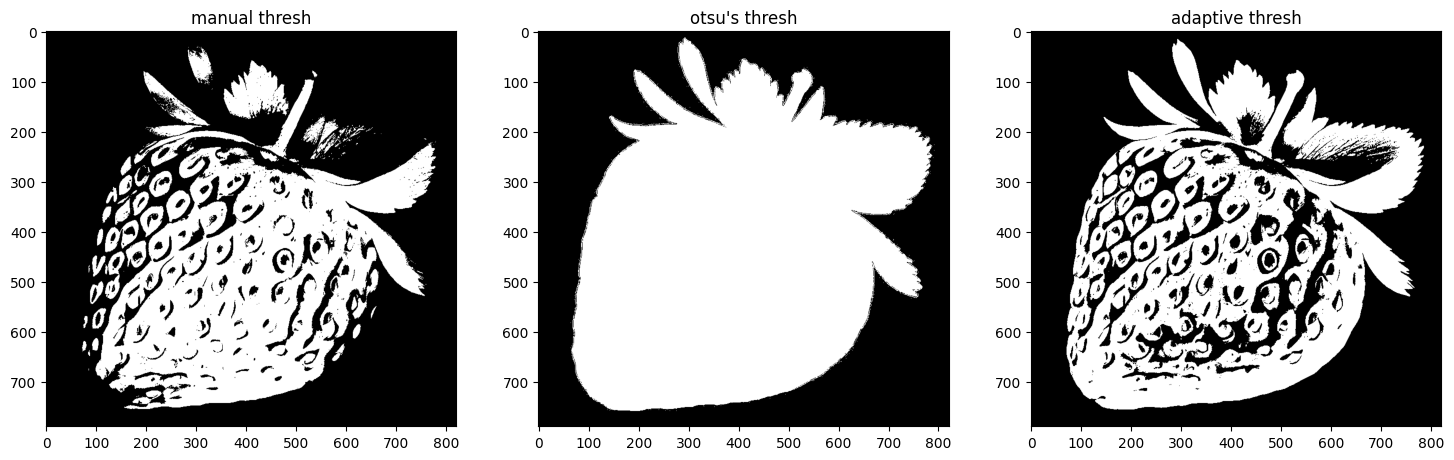

In [12]:
thresh1, bw1 = cv2.threshold(equ, thresh=90, maxval=255, type=cv2.THRESH_BINARY_INV) # manually selected threshold, low values to 255
thresh2, bw2 = cv2.threshold(equ, thresh=127, maxval=255, type=cv2.THRESH_OTSU)  # otsu's method
bw3 = cv2.adaptiveThreshold(img,255,cv2.ADAPTIVE_THRESH_GAUSSIAN_C, cv2.THRESH_BINARY,301,3) # adaptive thresholding.
# 301 is block size, 3 is sigma (standard deviation)

bw2 = np.invert(bw2) # invert image, i.e. swap black and whhite
bw3 = np.invert(bw3)

plt.figure(figsize=(18, 8))
plt.subplot(1,3,1)
plt.imshow(bw1,cmap="gray")
plt.title("manual thresh")
plt.subplot(1,3,2)
plt.imshow(bw2,cmap="gray")
plt.title("otsu's thresh")
plt.subplot(1,3,3)
plt.imshow(bw3,cmap="gray")
plt.title("adaptive thresh")

plt.show()

Morphological operations for separating stawberries

Text(0.5, 1.0, 'close & erosion2')

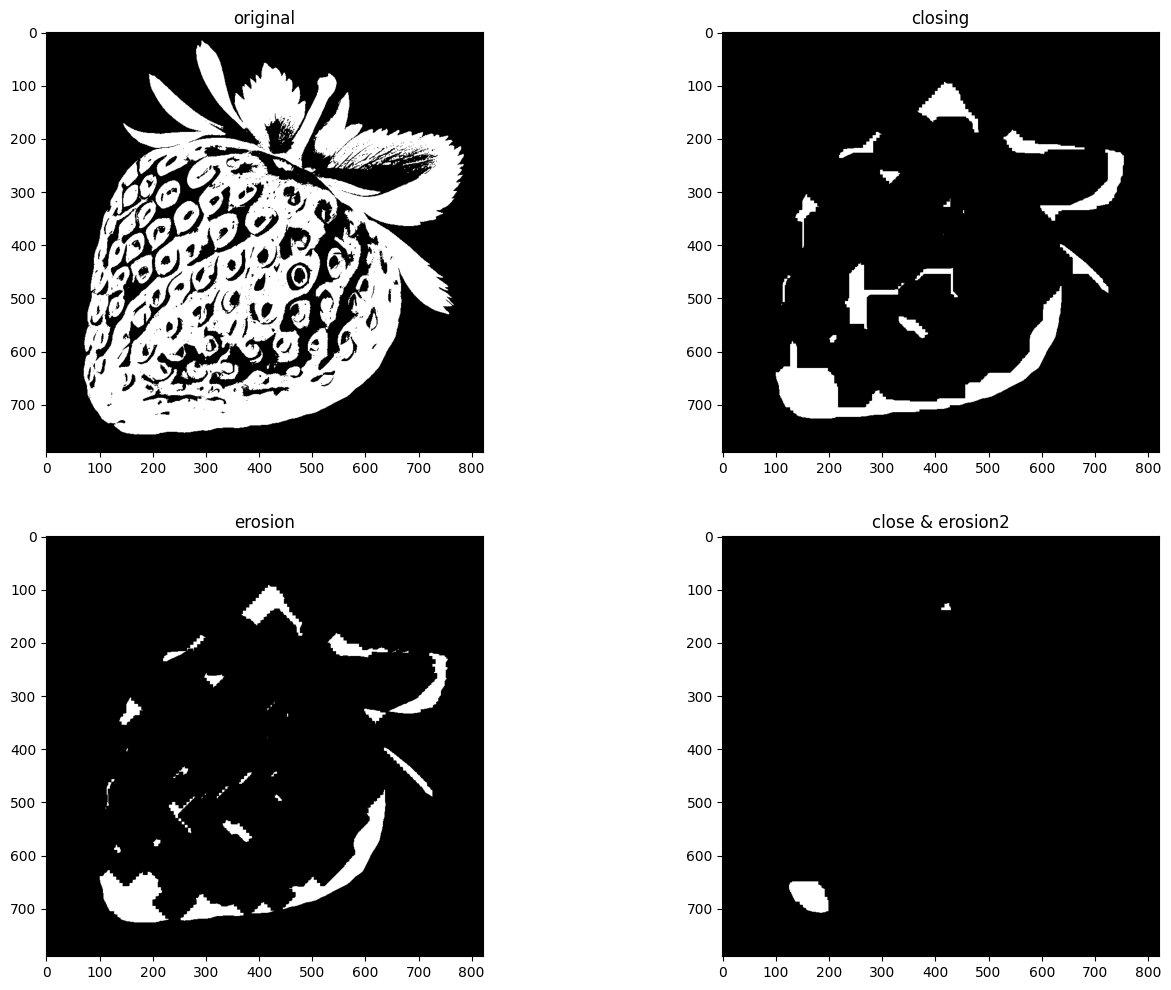

In [13]:
# create a structuring element
kernel = np.ones((3,3),np.uint8)
# closing
closing = cv2.morphologyEx(bw3, cv2.MORPH_CLOSE, kernel, iterations=4)

# erosion
kernel = cv2.getStructuringElement(cv2.MORPH_CROSS,(13,13))
erosion = cv2.erode(closing,kernel,iterations = 5)

# closing
kernel = np.ones((11,11),np.uint8)
closing = cv2.morphologyEx(erosion, cv2.MORPH_CLOSE, kernel, iterations=5)

# erosion
kernel = np.ones((7,7),np.uint8)
erosion2 = cv2.erode(closing,kernel,iterations = 6)

# remove boarder pixels
erosion2[:50, :] = 0
erosion2[:, :50] = 0
erosion2[-50:, :] = 0
erosion2[:, -50:] = 0

plt.figure(figsize=(16, 12))
plt.subplot(2,2,1)
plt.imshow(bw3,cmap="gray")
plt.title("original")
plt.subplot(2,2,2)
plt.imshow(closing,cmap="gray")
plt.title("closing")
plt.subplot(2,2,3)
plt.imshow(erosion,cmap="gray")
plt.title("erosion")
plt.subplot(2,2,4)
plt.imshow(erosion2,cmap="gray")
plt.title("close & erosion2")

Find centroids of isolated clusters/blobs

There are 2 strawberries


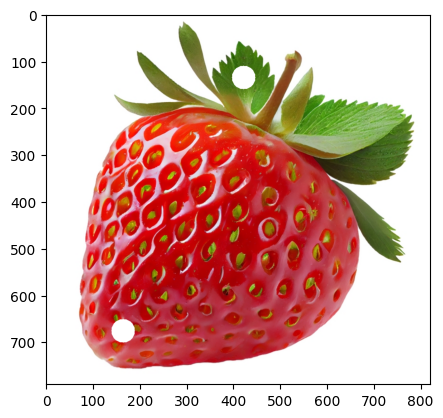

In [14]:
display = colour.copy()
labels, nlabels = ndimage.label(erosion2)  # Label features in an array. Any non-zero values in input are counted as features and zero values are considered the background.
print("There are " + str(nlabels) + " strawberries")

centroid = ndimage.center_of_mass(erosion2, labels, np.arange(nlabels) + 1 ) # calculate the center of mass of the values of an array at labels.

# draw circles representing the centroids
for cen in centroid:
  display = cv2.circle(display, (cen[1].astype(int), cen[0].astype(int)), radius=25, color=(255, 255, 255), thickness=-1)

plt.figure()
plt.imshow(display[:,:,::-1])


Use the HSV colour space as an alternative to the RGB colour space

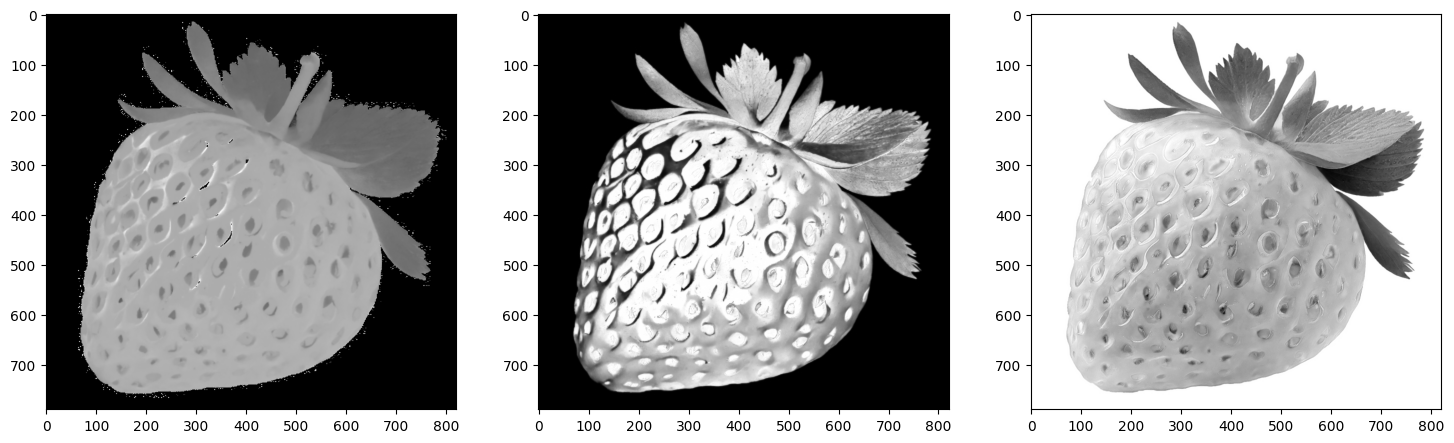

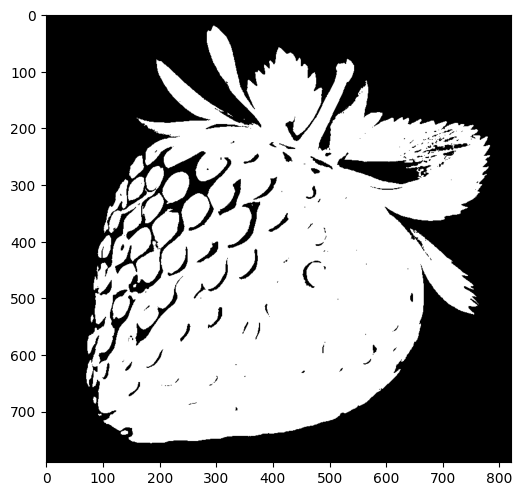

In [15]:
plt.figure(figsize=(18, 6))
plt.subplot(1,3,1)
plt.imshow(hsv_img[:,:,0], cmap="gray")
plt.subplot(1,3,2)
plt.imshow(hsv_img[:,:,1], cmap="gray") # select this channel
plt.subplot(1,3,3)
plt.imshow(hsv_img[:,:,2], cmap="gray")

hsv_c = (255*hsv_img[:,:,1]).astype(np.uint8) # scale data from [0, 1] to [0, 255] and convert to uint8 type

thresh_hsv, bw_hsv = cv2.threshold(hsv_c, thresh=128, maxval=255, type=cv2.THRESH_OTSU) # manually selected threshold, low values to 255

plt.figure(figsize=(6, 6))
plt.imshow(bw_hsv,cmap="gray")


Total white pixels: 49640


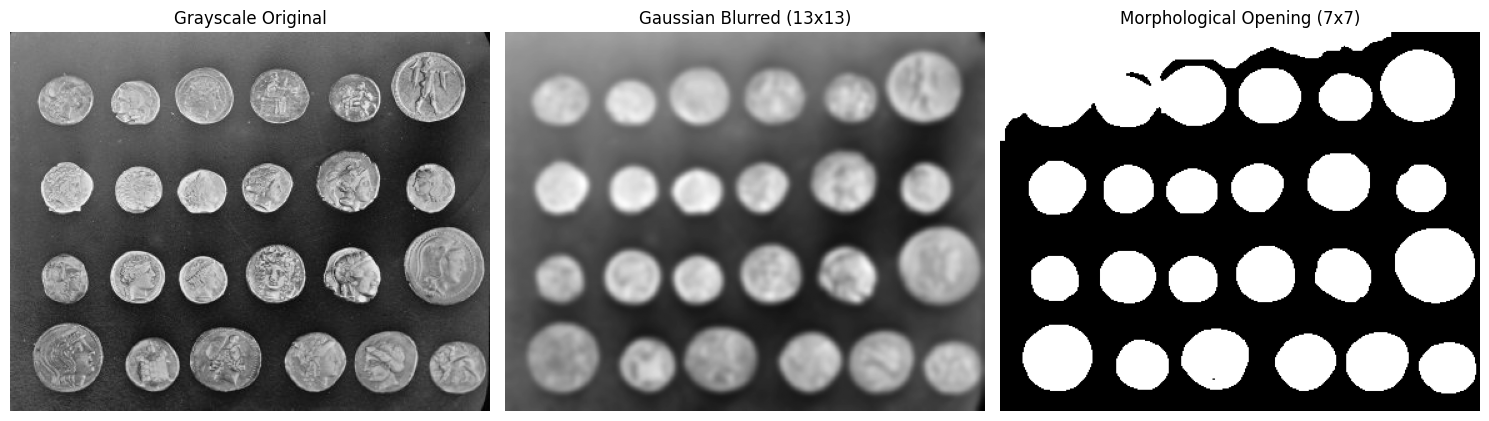

In [16]:
import cv2
import matplotlib.pyplot as plt
import numpy as np
from skimage import data # coins images

# 1. Load the coins image in grayscale mode
coins = data.coins()

# 2. Apply Gaussian blur (kernel size 13x13, sigma 0)
blurred = cv2.GaussianBlur(coins, (13, 13), 0)

# 3. Apply Otsu's thresholding (Coins -> 255 White, Background -> 0 Black)
_, binary = cv2.threshold(
    blurred, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU
)

# 4. Morphological opening operation with a 7x7 square kernel
kernel = np.ones((7, 7), np.uint8)
opened = cv2.morphologyEx(binary, cv2.MORPH_OPEN, kernel)

# Calculate total number of white pixels
white_pixel_count = np.sum(opened == 255)
print(f"Total white pixels: {white_pixel_count}")

# 5. Display grayscale, blurred, and resultant binary images side by side
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].imshow(coins, cmap="gray")
axes[0].set_title("Grayscale Original")
axes[0].axis("off")

axes[1].imshow(blurred, cmap="gray")
axes[1].set_title("Gaussian Blurred (13x13)")
axes[1].axis("off")

axes[2].imshow(opened, cmap="gray")
axes[2].set_title("Morphological Opening (7x7)")
axes[2].axis("off")

plt.tight_layout()
plt.show()

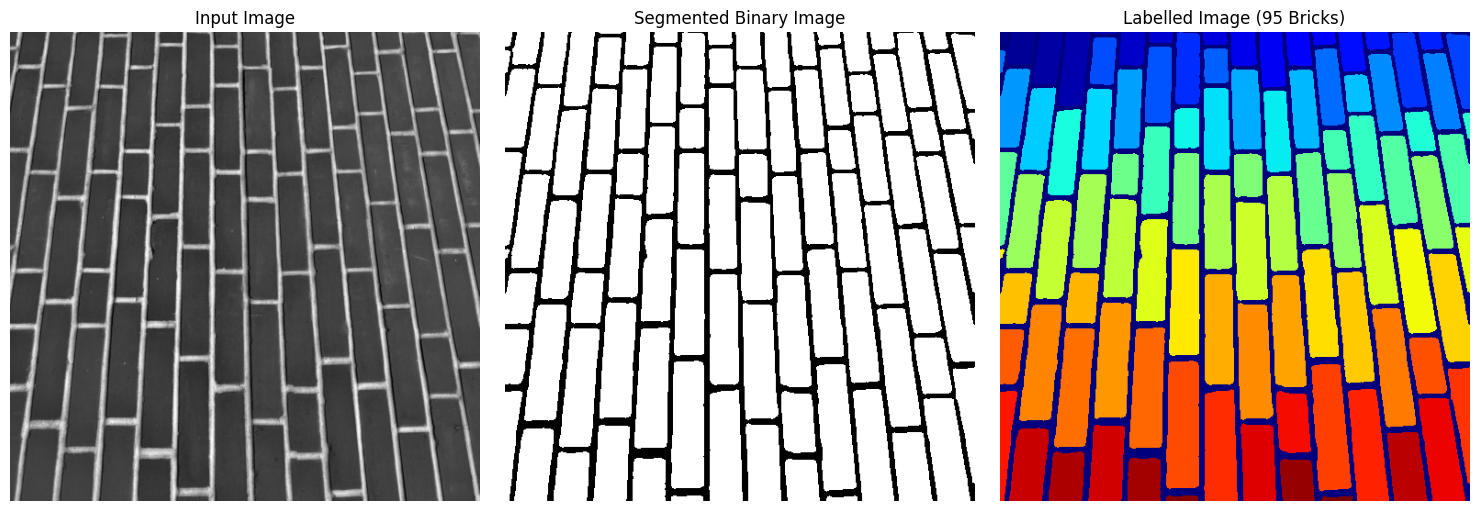

Total bricks detected: 95
Largest object label ID: 79
Largest brick area: 4754 pixels


In [17]:
import cv2
import matplotlib.pyplot as plt
import numpy as np
from scipy import ndimage
from skimage import data

# 1. Load the brick image in grayscale mode
brick = data.brick()

# 2. Apply Gaussian blur (kernel size 5x5, sigma 0)
blurred = cv2.GaussianBlur(brick, (5, 5), 0)

# 3. Apply Otsu's thresholding (Invert output so bricks are white and mortar is black)
_, binary = cv2.threshold(
    blurred, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU
)

# 4. Morphological opening operation using a disk-shaped structuring element (diameter 5)
kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (5, 5))
opened = cv2.morphologyEx(binary, cv2.MORPH_OPEN, kernel)

# 5. Assign unique integer labels to distinct white objects
labeled_image, num_features = ndimage.label(opened)

# 6. Display input image, segmented image, and labelled image side-by-side
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].imshow(brick, cmap="gray")
axes[0].set_title("Input Image")
axes[0].axis("off")

axes[1].imshow(opened, cmap="gray")
axes[1].set_title("Segmented Binary Image")
axes[1].axis("off")

axes[2].imshow(labeled_image, cmap="jet")
axes[2].set_title(f"Labelled Image ({num_features} Bricks)")
axes[2].axis("off")

plt.tight_layout()
plt.show()

# 7. Calculate pixel area for each labelled object (excluding background label 0)
pixel_counts = np.bincount(labeled_image.ravel())
object_areas = pixel_counts[1:]  # Index 0 is background

# 8. Identify the largest brick object index and its area
largest_label_id = np.argmax(object_areas) + 1  # 1-based label ID assigned by ndimage.label
largest_area = object_areas[largest_label_id - 1]

print(f"Total bricks detected: {num_features}")
print(f"Largest object label ID: {largest_label_id}")
print(f"Largest brick area: {largest_area} pixels")

Image shape: (500, 500, 3), dtype: uint8
Total white pixels after closing: 84795


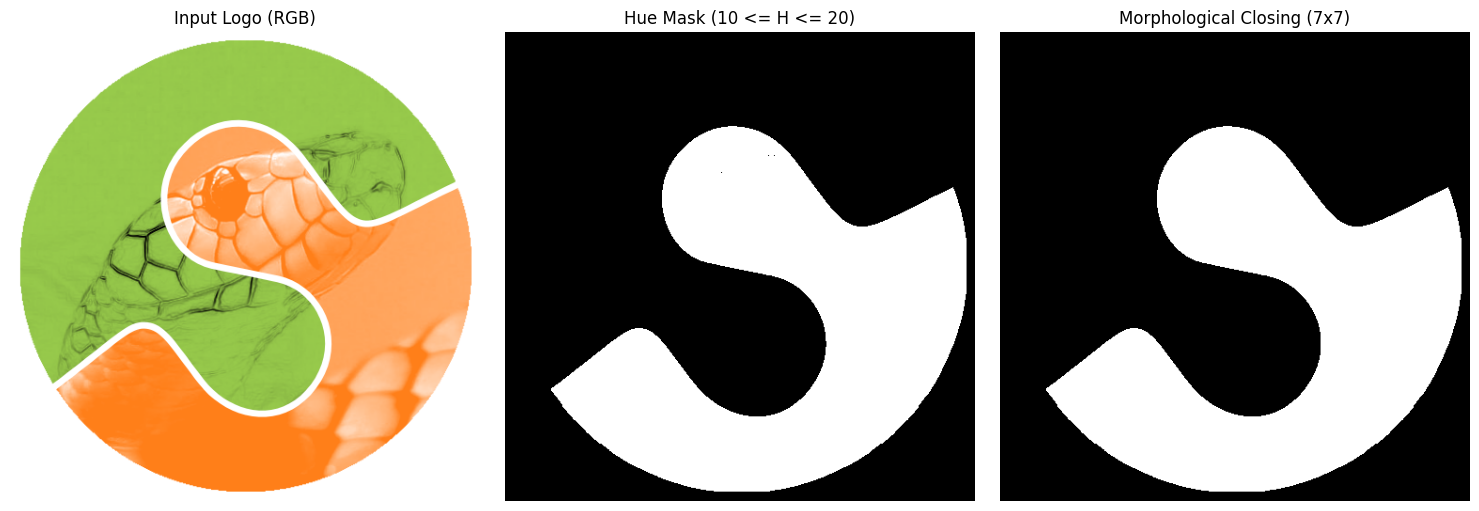

In [18]:
import cv2
import matplotlib.pyplot as plt
import numpy as np
from skimage import data

# 1. Load scikit-image logo dataset and ensure 3-channel RGB
logo = data.logo()
logo_rgb = logo[:, :, :3]  # Extract RGB channels (discard alpha channel)

print(f"Image shape: {logo_rgb.shape}, dtype: {logo_rgb.dtype}")

# 2. Convert from native RGB to HSV color space
hsv = cv2.cvtColor(logo_rgb, cv2.COLOR_RGB2HSV)

# 3. Isolate the Hue (H) channel (index 0)
hue_channel = hsv[:, :, 0]

# 4 & 5. Create binary mask for orange hue range (10 <= H <= 20)
mask = np.zeros(hue_channel.shape, dtype=np.uint8)
mask[(hue_channel >= 10) & (hue_channel <= 20)] = 255

# 6. Apply morphological closing using a 7x7 square kernel
kernel = np.ones((7, 7), np.uint8)
closed_mask = cv2.morphologyEx(mask, cv2.MORPH_CLOSE, kernel)

# Calculate total white pixels (non-zero)
white_pixel_count = np.sum(closed_mask == 255)
print(f"Total white pixels after closing: {white_pixel_count}")

# Display side-by-side results
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].imshow(logo_rgb)
axes[0].set_title("Input Logo (RGB)")
axes[0].axis("off")

axes[1].imshow(mask, cmap="gray")
axes[1].set_title("Hue Mask (10 <= H <= 20)")
axes[1].axis("off")

axes[2].imshow(closed_mask, cmap="gray")
axes[2].set_title("Morphological Closing (7x7)")
axes[2].axis("off")

plt.tight_layout()
plt.show()